# Workload 2: block size, quantile stability and what breaks the GEV

This notebook does one job: decide **how the GEV tail estimate of the segmentation workload (`workload2`) is set up** (block size, extremal-index gap, bootstrap block length) and **why the GEV does not fit all runs**. It does not derive budgets; `analysis_workload2.ipynb` does that with the values chosen here.

| # | Question | How it is answered |
|---|---|---|
| 1 | Which block size `b`? | stability of the **bound that the budget uses** (GEV bound at `P_GEV`) over `b`, over the run length and against the empirical quantile; goodness of fit (calibrated by a parametric bootstrap) and tail plots as diagnostics |
| 2 | Is the data stationary? | start-up transient, drift of the level, trend test, halves, autocorrelation, common drift of the two instances; effect of removing the drift |
| 3 | Which assumption of the block-maxima GEV does the workload break? | independence, stationarity, one regime for the tail (mixture of bulk and rare events), Poisson arrival of the events, content vs platform |

**Acceptance criteria** (defined in the configuration cell; the thresholds are choices of this study, not universal):

1. the block size must give at least `MIN_BLOCKS` blocks and be at least 10 × `RUNS_R` jobs (a block must be longer than the clusters of exceedances);
2. **stability:** the GEV bound at `P_GEV` varies by at most `SPREAD_MAX` over the admissible block sizes, and by at most `HALF_MAX` between the full run and each half of it;
3. **agreement:** the GEV bound is within `EMP_MAX` of the empirical (1−p) quantile of the same run;
4. the upper tail in the QQ/return-level plots has no systematic departure;
5. the goodness-of-fit p-value is reported but is **not** a gate: it is dominated by the body of the block maxima, and not rejecting does not prove a good fit nor does rejecting make the bound unusable.

A run that fails 2 or 3 should not use the GEV bound; it falls back to the empirical bound with the moving-block bootstrap (already in the procedure).

## 0. Configuration and helpers

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import genextreme, kstest, kendalltau, ks_2samp, skew, kurtosis, expon

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", "{:.3f}".format)

# ======================== EDIT HERE ========================
RQ2 = Path("../workload2")
SCENARIOS  = {"single_core": ["instance0"], "multi_core": ["instance0", "instance1"]}
CONDITIONS = ["baseline1", "cache", "memory", "baseline2"]
P_GEV = 1e-3                                  # the p at which the GEV bound is used
RUNS_R = 50                                   # runs-method gap (jobs) between clusters of exceedances
BLOCK_GRID = [100, 200, 300, 500, 750, 1000]
MIN_BLOCKS = 50                               # criterion 1: at least this many blocks
MIN_B = 10 * RUNS_R                           # criterion 1: a block is longer than the clusters
BLOCK_CHOSEN = 500                            # the block size that the analysis notebook uses (checked in section 1)
L_BOOT = 500                                  # moving-block bootstrap block length (checked in section 1.5)
SPREAD_MAX, HALF_MAX, EMP_MAX = 0.05, 0.10, 0.10
GOF_REPS, GOF_GRID = 100, [300, 500, 750, 1000]       # parametric-bootstrap replicates (smallest p-value = 1/(reps+1))
EVENT_FACTOR = 1.15                           # a job whose C is above EVENT_FACTOR x the median C is an "event" (section 3)
ROLL = 1000                                   # rolling window (jobs) of the level plots
# ===========================================================

rng = np.random.default_rng(0)
RUNS = [(s, c, i) for s in SCENARIOS for c in CONDITIONS for i in SCENARIOS[s]]
label = lambda r: f"{r[0][:5]}/{r[1]}/{r[2][-1]}"

def load(s, c, i):
    d = pd.read_csv(RQ2 / "results" / s / c / f"{i}.csv", usecols=["job_id", "skipped", "warmup", "cpu_ns", "start_ns"])
    return d[(d.skipped == 0) & (d.warmup == 0)].sort_values("job_id").reset_index(drop=True)

frames = {r: load(*r) for r in RUNS}
X = {r: f.cpu_ns.to_numpy() / 1e6 for r, f in frames.items()}                # C (ms) per run, job order
print(pd.Series({label(r): len(x) for r, x in X.items()}).to_string())

from math import gamma, log
from scipy.optimize import minimize

def _nll(t, m):                                    # GEV negative log-likelihood, scipy's c = -xi
    c, loc, ls = t; z = (m - loc) / np.exp(ls)
    if abs(c) < 1e-8: return float(np.sum(ls + z + np.exp(-z)))
    u = 1 - c * z
    return 1e12 if np.any(u <= 0) else float(np.sum(ls + (1 - 1 / c) * np.log(u) + u ** (1 / c)))

def fit_gev(m, multi=True):
    # maximum-likelihood GEV fit (c, loc, scale), scipy's convention: the same estimate as genextreme.fit, about 5x faster
    # (L-moment start, Nelder-Mead; multi=False uses only that start, for the bootstrap)
    m = np.sort(np.asarray(m, float)); n = len(m); i = np.arange(1, n + 1)
    b0 = m.mean(); b1 = np.sum((i - 1) / (n - 1) * m) / n; b2 = np.sum((i - 1) * (i - 2) / ((n - 1) * (n - 2)) * m) / n
    l1, l2, l3 = b0, 2 * b1 - b0, 6 * b2 - 6 * b1 + b0
    z = 2 / (3 + l3 / l2) - log(2) / log(3); k = 7.8590 * z + 2.9554 * z * z
    k = k if abs(k) > 1e-6 else 1e-6
    sc = l2 * k / ((1 - 2.0 ** -k) * gamma(1 + k)); loc = l1 - sc * (1 - gamma(1 + k)) / k
    best = None
    for k0 in ((k, -0.2, 0.2) if multi else (k,)):
        r = minimize(_nll, [k0, loc if k0 == k else np.median(m), np.log(abs(sc))], args=(m,), method="Nelder-Mead",
                     options=dict(xatol=1e-7, fatol=1e-10, maxiter=4000))
        if best is None or r.fun < best.fun: best = r
    return best.x[0], best.x[1], float(np.exp(best.x[2]))

def block_maxima(x, b):
    k = len(x) // b
    return x[: k * b].reshape(k, b).max(axis=1)

def extremal_index(x, p=P_GEV, r=RUNS_R):
    idx = np.flatnonzero(x > np.quantile(x, 1 - p))
    return (1 + np.sum(np.diff(idx) > r)) / len(idx)

def gev_bound(x, b, p=P_GEV, th=None, r=RUNS_R):
    th = extremal_index(x, p, r) if th is None else th
    c, loc, sc = fit_gev(block_maxima(x, b))
    return genextreme.ppf((1 - p) ** (b * th), c, loc, sc), -c

def gof_p(m, reps=GOF_REPS, seed=1):
    # KS test of the block maxima against the GEV fitted to them; p-value from a parametric bootstrap (the parameters are estimated)
    g = np.random.default_rng(seed)
    c, loc, sc = fit_gev(m)
    d0 = kstest(m, genextreme.cdf, args=(c, loc, sc)).statistic
    ds = []
    for _ in range(reps):
        y = genextreme.rvs(c, loc, sc, size=len(m), random_state=g)
        c2, l2, s2 = fit_gev(y, multi=False)
        ds.append(kstest(y, genextreme.cdf, args=(c2, l2, s2)).statistic)
    return (1 + sum(d >= d0 for d in ds)) / (reps + 1)

def mad_sigma(x):
    return 1.4826 * np.median(np.abs(x - np.median(x)))

def acf(x, lags):
    z = x - x.mean(); n = len(z)
    f = np.fft.rfft(z, 2 * n); a = np.fft.irfft(f * np.conj(f))[:n]
    return a[lags] / a[0]

singl/baseline1/0    50000
singl/cache/0        49999
singl/memory/0       50000
singl/baseline2/0    50000
multi/baseline1/0    50000
multi/baseline1/1    50000
multi/cache/0        50000
multi/cache/1        50000
multi/memory/0       49968
multi/memory/1       49968
multi/baseline2/0    50000
multi/baseline2/1    50000


## 1. Block size

### 1.1 Quantile stability
For every run and instance: the GEV bound of the per-job (1−p) level at `P_GEV` (block maxima of size `b`, extremal index θ from the runs estimator) for every block size of the grid. `emp` is the empirical (1−p) quantile and θ the extremal index.
`spread` = max/min of the bound over the admissible block sizes (criterion 1: enough blocks and `b ≥ MIN_B`); `halves` = max/min of the bound at `BLOCK_CHOSEN` between the full run and its first and second half; `vs emp` = bound at `BLOCK_CHOSEN` / emp − 1.
**Reading the table:** a column of the grid changes little when the bound is insensitive to `b`. A bound that falls steadily with `b` (large spread) means the model is extrapolating a feature that is not in the data.

In [2]:
rows, B = [], {}
for r in RUNS:
    x = X[r]; th = extremal_index(x)
    adm = [b for b in BLOCK_GRID if b >= MIN_B and len(x) // b >= MIN_BLOCKS]
    B[r] = {b: gev_bound(x, b, th=th)[0] for b in BLOCK_GRID if len(x) // b >= 20}
    v = [B[r][b] for b in adm]
    h = len(x) // 2; hb = [gev_bound(x[:h], BLOCK_CHOSEN)[0], gev_bound(x[h:], BLOCK_CHOSEN)[0]]
    full = B[r][BLOCK_CHOSEN]
    emp = np.quantile(x, 1 - P_GEV)
    rows.append(dict(run=label(r), emp=emp, theta=th, **{f"b={b}": B[r].get(b, np.nan) for b in BLOCK_GRID},
                     spread=max(v) / min(v), halves=max([full] + hb) / min([full] + hb), vs_emp=full / emp - 1))
stab = pd.DataFrame(rows).set_index("run")
stab["stable"] = (stab.spread - 1 <= SPREAD_MAX) & (stab.halves - 1 <= HALF_MAX) & (stab.vs_emp.abs() <= EMP_MAX)
display(stab.round(3))
print(f"stable runs: {int(stab.stable.sum())} of {len(stab)}   (spread <= {SPREAD_MAX:.0%}, halves <= {HALF_MAX:.0%}, |vs emp| <= {EMP_MAX:.0%}); b = {BLOCK_CHOSEN}")

,emp,theta,b=100,b=200,b=300,b=500,b=750,b=1000,spread,halves,vs_emp,stable
run,,,,,,,,,,,,
singl/baseline1/0,51.087,0.700,51.868,51.547,51.298,50.957,50.673,50.468,1.010,1.011,-0.003,True
singl/cache/0,54.655,0.620,56.146,55.738,55.393,54.921,54.466,54.195,1.008,1.026,0.005,True
singl/memory/0,54.236,0.580,55.287,54.943,54.630,54.221,53.868,53.605,1.011,1.006,-0.000,True
singl/baseline2/0,50.784,0.680,51.669,51.303,51.103,50.909,50.701,50.543,1.007,1.013,0.002,True
multi/baseline1/0,51.866,0.740,52.237,52.068,51.922,51.701,51.365,51.226,1.009,1.040,-0.003,True
multi/baseline1/1,51.530,0.740,52.198,52.006,51.866,51.708,51.450,51.289,1.008,1.012,0.003,True
multi/cache/0,42.442,0.480,43.882,43.360,43.108,42.992,42.849,42.860,1.003,1.018,0.013,True
multi/cache/1,54.592,0.540,57.058,55.791,55.197,54.944,54.685,54.644,1.006,1.021,0.006,True
multi/memory/0,60.060,0.400,85.368,68.319,62.782,60.081,58.883,57.606,1.020,1.138,0.000,False


stable runs: 10 of 12   (spread <= 5%, halves <= 10%, |vs emp| <= 10%); b = 500


### 1.2 Goodness of fit
KS test of the block maxima against the fitted GEV, with the p-value calibrated by a parametric bootstrap (`GOF_REPS` replicates; the smallest possible p-value is 1/(`GOF_REPS`+1) ≈ 0.01). `xi` is the fitted shape.
**Reading the table:** this is a diagnostic. A small p-value says the whole distribution of the maxima is not exactly a GEV; it does not say the bound at `P_GEV` is wrong (compare with 1.1).

In [3]:
rows = []
for r in RUNS:
    x = X[r]; row = dict(run=label(r))
    for b in GOF_GRID:
        if len(x) // b < 40: continue
        m = block_maxima(x, b); row[f"p b={b}"] = gof_p(m); row[f"xi b={b}"] = -fit_gev(m)[0]
    rows.append(row)
gof = pd.DataFrame(rows).set_index("run")
display(gof.round(2))

,p b=300,xi b=300,p b=500,xi b=500,p b=750,xi b=750,p b=1000,xi b=1000
run,,,,,,,,
singl/baseline1/0,0.010,0.240,0.010,0.340,0.010,0.340,0.020,0.470
singl/cache/0,0.010,0.230,0.010,0.310,0.010,0.430,0.010,0.530
singl/memory/0,0.010,0.220,0.010,0.300,0.010,0.360,0.010,0.410
singl/baseline2/0,0.010,0.140,0.010,0.190,0.010,0.250,0.010,0.270
multi/baseline1/0,0.470,0.390,0.500,0.480,0.310,0.570,0.140,0.600
multi/baseline1/1,0.010,0.330,0.020,0.420,0.080,0.530,0.220,0.570
multi/cache/0,0.010,0.530,0.010,0.490,0.020,0.570,0.020,0.560
multi/cache/1,0.010,0.610,0.200,0.460,0.150,0.540,0.430,0.540
multi/memory/0,0.010,0.740,0.010,0.600,0.010,0.540,0.010,0.660


### 1.3 Stability against the block size (figure)
Left: the GEV bound divided by the empirical quantile, one line per run; the band is the ±`EMP_MAX` agreement criterion and the dotted line marks the minimum block size. Right: the GEV shape ξ.

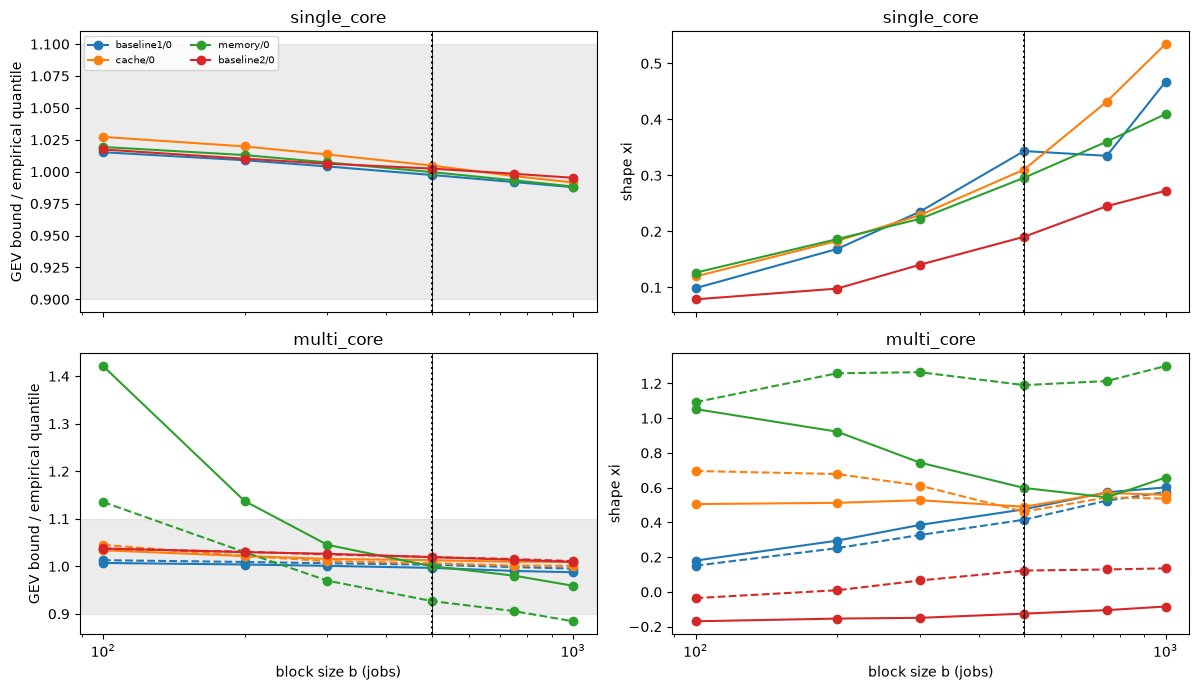

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
cols = dict(zip(CONDITIONS, ["tab:blue", "tab:orange", "tab:green", "tab:red"]))
for k, s in enumerate(SCENARIOS):
    for r in [r for r in RUNS if r[0] == s]:
        bs = [b for b in BLOCK_GRID if b in B[r]]
        emp = np.quantile(X[r], 1 - P_GEV)
        ax[k, 0].plot(bs, [B[r][b] / emp for b in bs], "o-", color=cols[r[1]], ls="-" if r[2] == "instance0" else "--", label=f"{r[1]}/{r[2][-1]}")
        ax[k, 1].plot(bs, [-fit_gev(block_maxima(X[r], b))[0] for b in bs], "o-", color=cols[r[1]], ls="-" if r[2] == "instance0" else "--")
    ax[k, 0].axhspan(1 - EMP_MAX, 1 + EMP_MAX, color="grey", alpha=.15)
    for a in ax[k]: a.axvline(MIN_B, color="k", ls=":"); a.axvline(BLOCK_CHOSEN, color="k", lw=.6); a.set_xscale("log"); a.set_title(s)
    ax[k, 0].set_ylabel("GEV bound / empirical quantile"); ax[k, 1].set_ylabel("shape xi")
ax[1, 0].set_xlabel("block size b (jobs)"); ax[1, 1].set_xlabel("block size b (jobs)"); ax[0, 0].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

### 1.4 Upper-tail diagnostics at `BLOCK_CHOSEN`
Return-level plot of the block maxima (instances pooled): the dots are the observed maxima, the red line the fitted GEV, the dashed horizontal line the empirical (1−p) quantile of the jobs and the dotted vertical line the return period (in blocks) that the GEV needs to reach that level: `1 / (1 − (1−p)^(b θ))`. The bound is read where the red line meets the return period of `P_GEV`.
**Reading the figure:** the red line should follow the top dots; a systematic miss of the highest dots is a tail problem, a miss of the lowest dots is only the body.

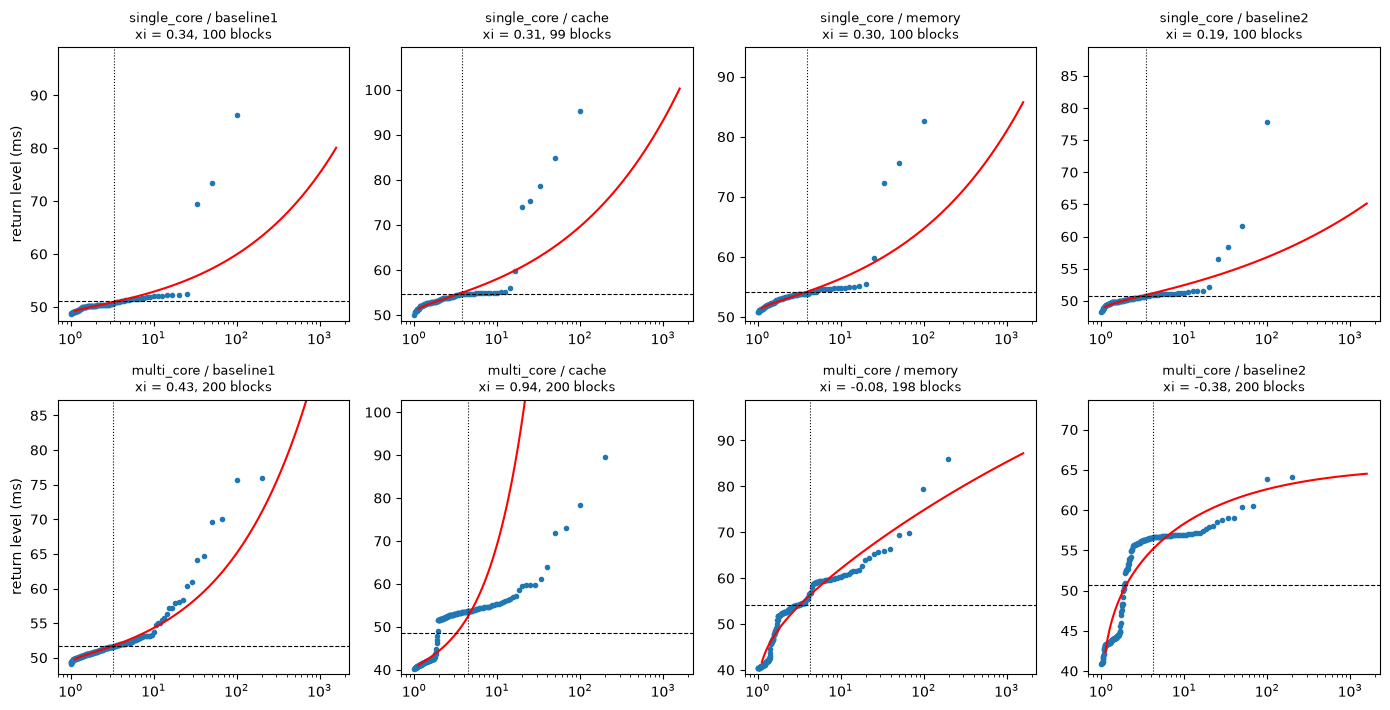

In [5]:
fig, ax = plt.subplots(len(SCENARIOS), len(CONDITIONS), figsize=(3.5 * len(CONDITIONS), 3.6 * len(SCENARIOS)), squeeze=False)
for k, s in enumerate(SCENARIOS):
    for j, c in enumerate(CONDITIONS):
        runs = [(s, c, i) for i in SCENARIOS[s]]
        m = np.concatenate([block_maxima(X[r], BLOCK_CHOSEN) for r in runs])
        cc, loc, sc = fit_gev(m)
        xs = np.sort(m); pr = np.arange(1, len(xs) + 1) / (len(xs) + 1)
        T = np.logspace(0.05, 3.2, 120)
        a = ax[k, j]
        a.semilogx(T, genextreme.isf(1 / T, cc, loc, sc), "r-"); a.scatter(1 / (1 - pr), xs, s=9)
        th = np.mean([extremal_index(X[r]) for r in runs]); emp = np.mean([np.quantile(X[r], 1 - P_GEV) for r in runs])
        a.axhline(emp, color="k", ls="--", lw=.8); a.axvline(1 / (1 - (1 - P_GEV) ** (BLOCK_CHOSEN * th)), color="k", ls=":", lw=.8)
        a.set_title(f"{s} / {c}\nxi = {-cc:.2f}, {len(m)} blocks", fontsize=9)
        a.set_ylim(xs.min() * 0.97, max(xs.max(), emp) * 1.15)
ax[0, 0].set_ylabel("return level (ms)"); ax[1, 0].set_ylabel("return level (ms)")
plt.tight_layout(); plt.show()

### 1.5 The other two parameters: `RUNS_R` and `L_BOOT`
**Extremal index θ against the gap `r`** of the runs estimator, and the GEV bound (at `BLOCK_CHOSEN`) it produces. A θ that plateaus identifies the length of the clusters; a θ that keeps falling means the exceedances are spread by something slower than a cluster (a drifting level, section 2), and then θ has no true value: a smaller θ lowers the bound, so the choice must be justified on the safe side.
**Bootstrap upper bound against the block length `L`** of the moving-block bootstrap (`B = 100` replicates): it must have reached its plateau at `L_BOOT`.

In [6]:
R_GRID = [1, 10, 20, 50, 100, 200, 500]
rows = []
for r in RUNS:
    x = X[r]
    rows.append(dict(run=label(r), **{f"theta r={g}": extremal_index(x, P_GEV, g) for g in R_GRID},
                     **{f"bound r={g}": gev_bound(x, BLOCK_CHOSEN, r=g)[0] for g in (20, 50, 100, 200)}))
rth = pd.DataFrame(rows).set_index("run")
display(rth.round(3))

L_GRID = [100, 300, 600, 1000, 2000, 5000]
def boot_ucb(x, p, L, Bn=100):
    n = len(x); k = n // L; ar = np.arange(L)
    q = [np.quantile(x[(rng.integers(0, n - L + 1, size=k)[:, None] + ar).ravel()], 1 - p) for _ in range(Bn)]
    return np.quantile(q, .95)
rows = [dict(run=label(r), emp=np.quantile(X[r], 1 - P_GEV), **{f"L={L}": boot_ucb(X[r], P_GEV, L) for L in L_GRID}) for r in RUNS]
display(pd.DataFrame(rows).set_index("run").round(3))

,theta r=1,theta r=10,theta r=20,theta r=50,theta r=100,theta r=200,theta r=500,bound r=20,bound r=50,bound r=100,bound r=200
run,,,,,,,,,,,
singl/baseline1/0,0.920,0.720,0.700,0.700,0.580,0.520,0.340,50.957,50.957,51.207,51.360
singl/cache/0,0.760,0.700,0.700,0.620,0.540,0.480,0.320,54.635,54.921,55.261,55.563
singl/memory/0,0.840,0.780,0.720,0.580,0.540,0.400,0.260,53.840,54.221,54.352,54.934
singl/baseline2/0,0.820,0.740,0.720,0.680,0.600,0.540,0.400,50.842,50.909,51.057,51.185
multi/baseline1/0,0.900,0.820,0.760,0.740,0.720,0.660,0.500,51.656,51.701,51.746,51.896
multi/baseline1/1,0.840,0.780,0.780,0.740,0.740,0.640,0.500,51.635,51.708,51.708,51.919
multi/cache/0,0.820,0.600,0.520,0.480,0.460,0.460,0.380,42.858,42.992,43.066,43.066
multi/cache/1,0.880,0.700,0.660,0.540,0.520,0.440,0.360,54.522,54.944,55.028,55.417
multi/memory/0,0.800,0.580,0.500,0.400,0.400,0.340,0.320,58.810,60.081,60.081,61.119


,emp,L=100,L=300,L=600,L=1000,L=2000,L=5000
run,,,,,,,
singl/baseline1/0,51.087,51.325,51.327,51.256,51.345,51.325,51.338
singl/cache/0,54.655,54.807,54.850,54.851,54.852,54.811,54.897
singl/memory/0,54.236,54.403,54.401,54.508,54.602,54.501,54.445
singl/baseline2/0,50.784,50.897,50.956,50.968,50.947,50.989,50.952
multi/baseline1/0,51.866,52.128,52.084,52.200,52.497,52.212,52.745
multi/baseline1/1,51.530,51.806,51.712,51.723,51.717,51.712,51.806
multi/cache/0,42.442,42.572,42.661,42.772,42.663,42.664,42.607
multi/cache/1,54.592,55.138,55.138,54.990,55.169,55.135,55.139
multi/memory/0,60.060,60.311,60.385,60.427,60.424,60.436,60.723


### 1.6 Verdict on the settings
The table gathers, per run, the criteria of the introduction. `estimator` says what the budget should use for that run.

In [7]:
verdict = stab[["emp", "spread", "halves", "vs_emp", "stable"]].join(gof[[f"p b={BLOCK_CHOSEN}", f"xi b={BLOCK_CHOSEN}"]])
verdict["estimator"] = np.where(verdict.stable, "GEV bound", "empirical (bootstrap) bound")
display(verdict.round(3))

,emp,spread,halves,vs_emp,stable,p b=500,xi b=500,estimator
run,,,,,,,,
singl/baseline1/0,51.087,1.010,1.011,-0.003,True,0.010,0.344,GEV bound
singl/cache/0,54.655,1.008,1.026,0.005,True,0.010,0.310,GEV bound
singl/memory/0,54.236,1.011,1.006,-0.000,True,0.010,0.296,GEV bound
singl/baseline2/0,50.784,1.007,1.013,0.002,True,0.010,0.190,GEV bound
multi/baseline1/0,51.866,1.009,1.040,-0.003,True,0.505,0.476,GEV bound
multi/baseline1/1,51.530,1.008,1.012,0.003,True,0.020,0.416,GEV bound
multi/cache/0,42.442,1.003,1.018,0.013,True,0.010,0.490,GEV bound
multi/cache/1,54.592,1.006,1.021,0.006,True,0.198,0.462,GEV bound
multi/memory/0,60.060,1.020,1.138,0.000,False,0.010,0.599,empirical (bootstrap) bound


## 2. Is the data stationary?

The block-maxima theory needs the process to be stationary (and weakly dependent). The segmentation task does the same work in every period (the same network on an input of the same size), so its C should be a stationary process around a constant level. This section looks for what contradicts that.

### 2.1 Tests
- `first job / median`, `first 200 / median`: start-up transient (cold caches) beyond the warm-up.
- `level range (σ)`: range of the medians of consecutive blocks of 1000 jobs, in units of the robust standard deviation of C. For an iid series the range would be about 0.1–0.3 σ (the median of 1000 jobs has σ/√1000 · 1.25).
- `Kendall τ (p)`: monotone trend of the block medians.
- `halves p50`, `halves p99.9`: second half / first half; `KS p`: two-sample KS between the halves.
- `acf`: autocorrelation of C at the lags shown. An iid series has 0; the extremal index handles dependence between nearby exceedances, but not a slowly drifting level.

In [8]:
rows = []
for r in RUNS:
    x = X[r]; n = len(x); med = np.median(x); sg = mad_sigma(x)
    bm = np.median(x[: n // 1000 * 1000].reshape(-1, 1000), axis=1)
    tau, pt = kendalltau(np.arange(len(bm)), bm)
    h = n // 2; a_, b_ = x[:h], x[h:]
    ac = acf(x, [1, 10, 100, 500, 3269])
    rows.append(dict(run=label(r), first_job_over_median=x[0] / med, first200_over_median=np.median(x[:200]) / med,
                     level_range_sigma=(bm.max() - bm.min()) / sg, tau=tau, tau_p=pt,
                     halves_p50=np.median(b_) / np.median(a_), halves_p999=np.quantile(b_, .999) / np.quantile(a_, .999),
                     ks_p=ks_2samp(a_, b_).pvalue, **{f"acf{l}": v for l, v in zip([1, 10, 100, 500, 3269], ac)}))
stat = pd.DataFrame(rows).set_index("run")
display(stat.round(3))

,first_job_over_median,first200_over_median,level_range_sigma,tau,tau_p,halves_p50,halves_p999,ks_p,acf1,acf10,acf100,acf500,acf3269
run,,,,,,,,,,,,,
singl/baseline1/0,1.005,0.981,2.532,0.179,0.067,1.013,0.985,0.000,0.733,0.682,0.666,0.602,0.341
singl/cache/0,0.980,0.989,3.517,0.415,0.000,1.016,1.021,0.000,0.703,0.620,0.573,0.515,0.321
singl/memory/0,1.019,1.019,2.695,-0.104,0.288,0.994,0.985,0.000,0.739,0.656,0.604,0.473,0.186
singl/baseline2/0,1.033,1.009,2.929,-0.296,0.002,0.983,0.985,0.000,0.734,0.678,0.663,0.576,0.319
multi/baseline1/0,1.032,1.026,2.083,-0.438,0.000,0.974,0.961,0.000,0.746,0.740,0.705,0.651,0.448
multi/baseline1/1,1.027,1.024,1.993,-0.451,0.000,0.975,0.989,0.000,0.751,0.743,0.707,0.642,0.430
multi/cache/0,0.994,0.994,2.391,0.143,0.143,1.002,0.992,0.000,0.566,0.487,0.384,0.249,0.013
multi/cache/1,0.996,0.996,2.305,0.130,0.184,1.002,0.987,0.000,0.549,0.466,0.375,0.258,0.002
multi/memory/0,1.004,0.993,6.625,0.515,0.000,1.074,1.114,0.000,0.908,0.888,0.868,0.843,0.675


### 2.2 The level over the run
Rolling median (window `ROLL` jobs, line) and block maxima of `BLOCK_CHOSEN` jobs (dots) of every run, instance 0 (multi-core: dashed = instance 1). A stationary run has a flat line.

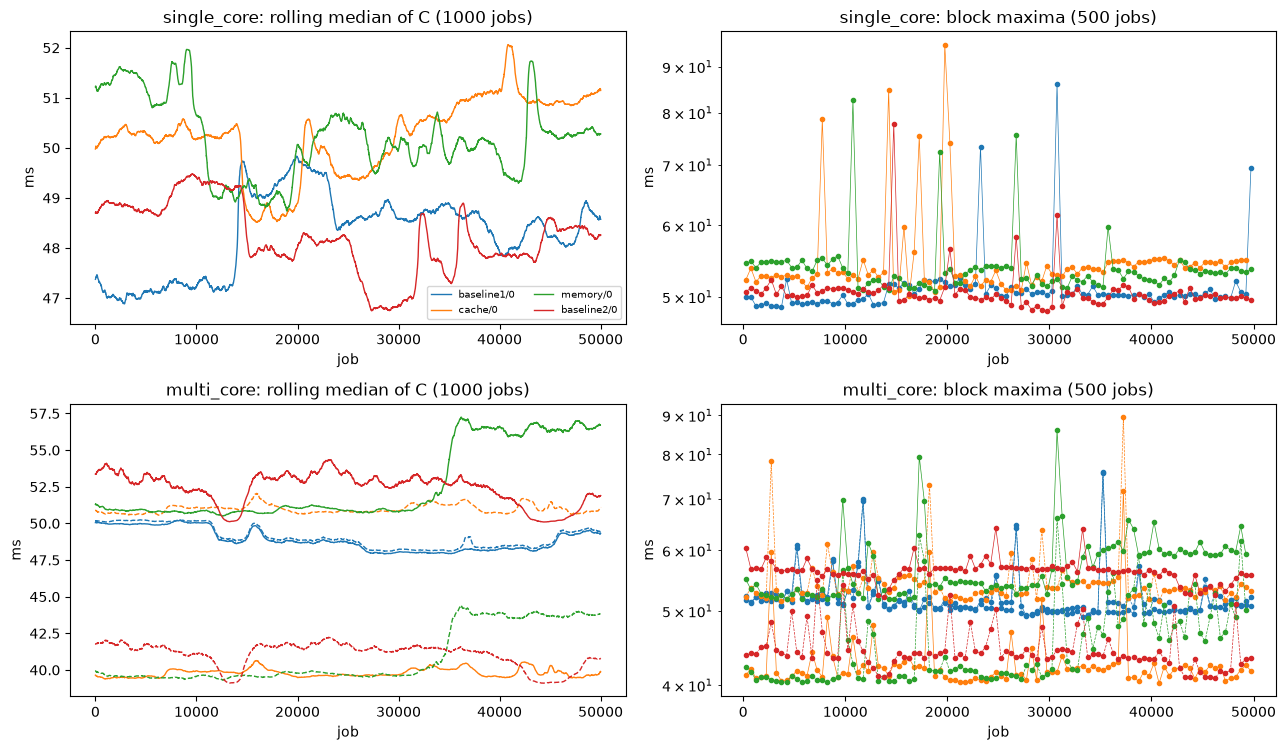

In [9]:
fig, ax = plt.subplots(len(SCENARIOS), 2, figsize=(13, 3.8 * len(SCENARIOS)), squeeze=False)
for k, s in enumerate(SCENARIOS):
    for r in [r for r in RUNS if r[0] == s]:
        x = X[r]; ls = "-" if r[2] == "instance0" else "--"
        roll = pd.Series(x).rolling(ROLL, center=True, min_periods=ROLL // 2).median()
        ax[k, 0].plot(roll.to_numpy(), ls=ls, color=cols[r[1]], label=f"{r[1]}/{r[2][-1]}", lw=1)
        m = block_maxima(x, BLOCK_CHOSEN); ax[k, 1].plot((np.arange(len(m)) + .5) * BLOCK_CHOSEN, m, ".", color=cols[r[1]], ls=ls, lw=.5)
    ax[k, 0].set_title(f"{s}: rolling median of C ({ROLL} jobs)"); ax[k, 1].set_title(f"{s}: block maxima ({BLOCK_CHOSEN} jobs)")
    ax[k, 0].set_ylabel("ms"); ax[k, 1].set_yscale("log"); ax[k, 1].set_ylabel("ms")
    ax[k, 0].set_xlabel("job"); ax[k, 1].set_xlabel("job")
ax[0, 0].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

### 2.3 Autocorrelation
Autocorrelation of C against the lag (instance 0). The shaded band is the 95 % band of an iid series. The curve stays outside it up to hundreds of jobs when the level wanders slowly.

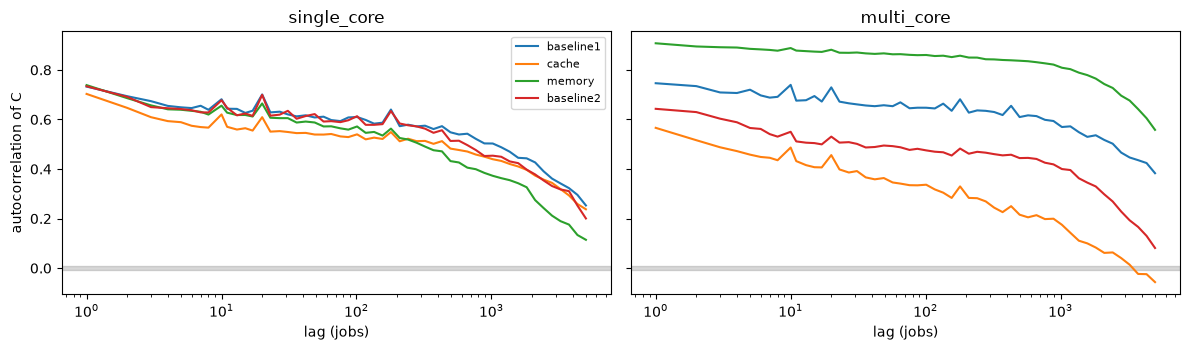

In [10]:
fig, ax = plt.subplots(1, len(SCENARIOS), figsize=(12, 3.6), sharey=True)
lags = np.unique(np.logspace(0, 3.7, 60).astype(int))
for k, s in enumerate(SCENARIOS):
    for c in CONDITIONS:
        ax[k].semilogx(lags, acf(X[(s, c, "instance0")], lags), color=cols[c], label=c)
    n = len(X[(s, "baseline1", "instance0")]); ax[k].axhspan(-1.96 / np.sqrt(n), 1.96 / np.sqrt(n), color="grey", alpha=.3)
    ax[k].set_title(s); ax[k].set_xlabel("lag (jobs)")
ax[0].set_ylabel("autocorrelation of C"); ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 2.4 Is the drift common to the two instances? (multi-core)
The two instances run on different cores of the same VM. If their block medians (and block maxima) move together, the drift comes from the platform (frequency, neighbours, thermal) and not from the task.

In [11]:
rows = []
for c in CONDITIONS:
    a, b = X[("multi_core", c, "instance0")], X[("multi_core", c, "instance1")]
    n = min(len(a), len(b)) // 1000 * 1000
    ma, mb = np.median(a[:n].reshape(-1, 1000), axis=1), np.median(b[:n].reshape(-1, 1000), axis=1)
    xa, xb = a[:n].reshape(-1, 1000).max(axis=1), b[:n].reshape(-1, 1000).max(axis=1)
    rows.append(dict(condition=c, corr_block_median=np.corrcoef(ma, mb)[0, 1], corr_block_max=np.corrcoef(xa, xb)[0, 1],
                     corr_block_max_log=np.corrcoef(np.log(xa), np.log(xb))[0, 1]))
display(pd.DataFrame(rows).set_index("condition").round(3))

,corr_block_median,corr_block_max,corr_block_max_log
condition,,,
baseline1,0.996,0.985,0.980
cache,0.992,0.992,0.991
memory,0.999,0.902,0.913
baseline2,0.991,0.386,0.411


### 2.5 Effect of the drift on the fit
The level is removed with the rolling median (`ROLL` jobs): `C_detrended = C − rolling median + global median`. The GEV bound is recomputed on it. The detrended series is **not** a valid input for the budget (the drift is a real part of what the task experiences); the table only shows how much of the instability is caused by the drift.
**Reading the table:** `p` is the bootstrap goodness-of-fit p-value at `BLOCK_CHOSEN`; `spread` the stability of the bound over the block sizes as in 1.1.

In [12]:
def detrend(x):
    return x - pd.Series(x).rolling(ROLL, center=True, min_periods=ROLL // 2).median().to_numpy() + np.median(x)

def spread_of(x):
    th = extremal_index(x); adm = [b for b in BLOCK_GRID if b >= MIN_B and len(x) // b >= MIN_BLOCKS]
    v = [gev_bound(x, b, th=th)[0] for b in adm]
    return max(v) / min(v)

rows = []
for r in RUNS:
    x, xd = X[r], detrend(X[r])
    rows.append(dict(run=label(r), p_orig=gof_p(block_maxima(x, BLOCK_CHOSEN)), p_detrended=gof_p(block_maxima(xd, BLOCK_CHOSEN)),
                     spread_orig=spread_of(x), spread_detrended=spread_of(xd),
                     bound_orig=gev_bound(x, BLOCK_CHOSEN)[0], bound_detrended=gev_bound(xd, BLOCK_CHOSEN)[0],
                     theta_orig=extremal_index(x), theta_detrended=extremal_index(xd)))
display(pd.DataFrame(rows).set_index("run").round(3))

,p_orig,p_detrended,spread_orig,spread_detrended,bound_orig,bound_detrended,theta_orig,theta_detrended
run,,,,,,,,
singl/baseline1/0,0.010,0.218,1.010,1.002,50.957,50.530,0.700,0.780
singl/cache/0,0.010,0.010,1.008,1.003,54.921,54.273,0.620,0.660
singl/memory/0,0.010,0.010,1.011,1.006,54.221,53.470,0.580,0.780
singl/baseline2/0,0.010,0.366,1.007,1.003,50.909,50.481,0.680,0.620
multi/baseline1/0,0.505,0.059,1.009,1.005,51.701,51.363,0.740,0.800
multi/baseline1/1,0.020,0.010,1.008,1.005,51.708,51.457,0.740,0.720
multi/cache/0,0.010,0.010,1.003,1.002,42.992,42.536,0.480,0.560
multi/cache/1,0.198,0.069,1.006,1.003,54.944,54.404,0.540,0.640
multi/memory/0,0.010,0.010,1.020,1.004,60.081,56.442,0.400,0.460


### 2.6 Steps in the level
The medians of consecutive blocks of `STEP_BLOCK` jobs. `largest_step_pct` is the largest change between two consecutive blocks, as a percentage of the run median; `steps_over_2sigma` counts the changes larger than twice the robust σ of the run. For the multi-core scenario, `corr_of_steps` is the correlation between the changes of instance 0 and instance 1, and `level_ratio` the ratio of their medians: steps that coincide point to the platform, and a persistent ratio different from 1 to a difference between the two cores.

In [13]:
STEP_BLOCK = 2500
rows, D = [], {}
for r in RUNS:
    x = X[r]; n = len(x) // STEP_BLOCK * STEP_BLOCK
    m = np.median(x[:n].reshape(-1, STEP_BLOCK), axis=1); D[r] = np.diff(m)
    rows.append(dict(run=label(r), blocks=len(m), median_min=m.min(), median_max=m.max(), range_pct=100 * (m.max() - m.min()) / np.median(x),
                     largest_step_pct=100 * np.abs(D[r]).max() / np.median(x), steps_over_2sigma=int((np.abs(D[r]) > 2 * mad_sigma(x)).sum())))
display(pd.DataFrame(rows).set_index("run").round(2))
rows = []
for c in CONDITIONS:
    ra, rb = ("multi_core", c, "instance0"), ("multi_core", c, "instance1"); k = min(len(D[ra]), len(D[rb]))
    rows.append(dict(condition=c, corr_of_steps=np.corrcoef(D[ra][:k], D[rb][:k])[0, 1], level_ratio=np.median(X[ra]) / np.median(X[rb])))
display(pd.DataFrame(rows).set_index("condition").round(3))

,blocks,median_min,median_max,range_pct,largest_step_pct,steps_over_2sigma
run,,,,,,
singl/baseline1/0,20,47.000,49.590,5.360,2.770,0
singl/cache/0,19,48.650,51.400,5.470,3.100,0
singl/memory/0,20,49.000,51.600,5.190,4.040,0
singl/baseline2/0,20,46.800,49.370,5.320,2.590,0
multi/baseline1/0,20,47.970,50.110,4.380,2.370,0
multi/baseline1/1,20,48.150,50.210,4.200,2.330,0
multi/cache/0,20,39.470,40.240,1.930,1.440,0
multi/cache/1,20,50.630,51.540,1.790,1.170,0
multi/memory/0,19,50.740,56.650,11.560,9.260,1


,corr_of_steps,level_ratio
condition,,
baseline1,0.991,0.996
cache,0.989,0.780
memory,0.997,1.284
baseline2,0.980,1.273


## 3. Which assumption of the GEV does the workload break?

The block-maxima GEV rests on: (a) **weak dependence**, (b) **stationarity**, (c) the tail of C comes from **one regime** (the observations are identically distributed, so the maxima of blocks are draws from one distribution in a maximum domain of attraction), and the extremal-index correction additionally needs (d) exceedances that arrive as **clusters of independent events**. This section measures each one.

### 3.1 One regime? Bulk and rare events
An **event** is a job above `EVENT_FACTOR` × the median C of its run: the task needed at least 15 % more CPU than a normal period. For the segmentation network the work per period is constant, so such a job is not caused by the content (3.4). The table compares the blocks that contain at least one event with those that do not.
**Reading the table:** if the maxima of event blocks sit far above those of bulk blocks (`gap`), the block maxima are a **mixture of two regimes** (a tight bulk and rare shocks), not draws from one GEV. `bimodality` above 0.55 is the usual sign of a bimodal distribution of the maxima. `dispersion` is the variance/mean of the events per block (1 for a Poisson process).

In [14]:
rows = []
EV = {}
for r in RUNS:
    x = X[r]; med = np.median(x); k = len(x) // BLOCK_CHOSEN
    blk = x[: k * BLOCK_CHOSEN].reshape(k, BLOCK_CHOSEN); mx = blk.max(axis=1)
    ev_blk = (blk > EVENT_FACTOR * med).sum(axis=1); has = ev_blk > 0
    EV[r] = np.flatnonzero(x > EVENT_FACTOR * med)
    n_ = len(mx); g1, g2 = skew(mx), kurtosis(mx)
    bc = (g1 ** 2 + 1) / (g2 + 3 * (n_ - 1) ** 2 / ((n_ - 2) * (n_ - 3)))
    rows.append(dict(run=label(r), events=len(EV[r]), per_100k=1e5 * len(EV[r]) / len(x), blocks_with_event=f"{has.sum()}/{k}",
                     max_bulk_blocks=np.median(mx[~has]) if (~has).any() else np.nan, max_event_blocks=np.median(mx[has]) if has.any() else np.nan,
                     gap=(np.median(mx[has]) / np.median(mx[~has])) if has.any() and (~has).any() else np.nan,
                     bimodality=bc, dispersion=ev_blk.var() / max(ev_blk.mean(), 1e-9)))
reg = pd.DataFrame(rows).set_index("run")
display(reg.round(3))

,events,per_100k,blocks_with_event,max_bulk_blocks,max_event_blocks,gap,bimodality,dispersion
run,,,,,,,,
singl/baseline1/0,5,10.000,3/100,50.241,73.373,1.460,0.900,2.150
singl/cache/0,14,28.001,6/99,53.103,77.024,1.450,0.877,3.716
singl/memory/0,9,18.000,4/100,53.062,73.965,1.394,0.872,3.354
singl/baseline2/0,10,20.000,4/100,50.089,59.934,1.197,0.837,5.100
multi/baseline1/0,9,18.000,7/100,50.698,60.901,1.201,0.784,1.354
multi/baseline1/1,9,18.000,7/100,50.844,60.402,1.188,0.814,1.354
multi/cache/0,12,24.000,8/100,41.621,50.429,1.212,0.830,1.713
multi/cache/1,11,22.000,7/100,53.287,63.845,1.198,0.826,1.799
multi/memory/0,372,744.476,38/99,53.498,59.969,1.121,0.584,34.665


Histogram of the block maxima (log scale), bulk blocks and event blocks coloured separately, for the single-core and the multi-core scenario under the memory enemy.

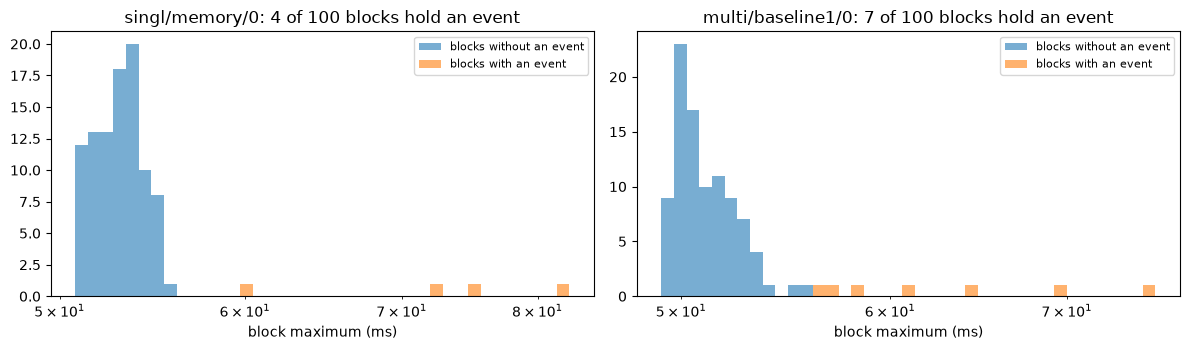

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for a, r in zip(ax, [("single_core", "memory", "instance0"), ("multi_core", "baseline1", "instance0")]):
    x = X[r]; med = np.median(x); k = len(x) // BLOCK_CHOSEN
    blk = x[: k * BLOCK_CHOSEN].reshape(k, BLOCK_CHOSEN); mx = blk.max(axis=1); has = (blk > EVENT_FACTOR * med).any(axis=1)
    bins = np.logspace(np.log10(mx.min()), np.log10(mx.max()), 40)
    a.hist(mx[~has], bins=bins, alpha=.6, label="blocks without an event"); a.hist(mx[has], bins=bins, alpha=.6, label="blocks with an event")
    a.set_xscale("log"); a.set_title(label(r) + f": {has.sum()} of {k} blocks hold an event"); a.set_xlabel("block maximum (ms)"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

### 3.2 Do the events arrive independently?
Distribution of the gaps between events (in jobs). For a Poisson process the gaps are exponential; `KS exp p` tests that after scaling by the mean gap. Clustering of events (short gaps beyond the exponential) breaks (d); a regular period (a timer, a periodic daemon) shows as a peak in the histogram. The gaps are plotted for the pooled single-core runs and the pooled multi-core runs.

,events,mean_gap,median_gap,share_gap_below_50,ks_exp_p
run,,,,,
singl/baseline1/0,5,6617.750,3703.000,0.500,NaN
singl/cache/0,14,964.231,1.000,0.615,0.000
singl/memory/0,9,3094.125,1.000,0.625,NaN
singl/baseline2/0,10,1782.556,1.000,0.556,NaN
multi/baseline1/0,9,4171.125,3009.500,0.250,NaN
multi/baseline1/1,9,4171.125,3009.500,0.250,NaN
multi/cache/0,12,3138.273,2538.000,0.364,0.083
multi/cache/1,11,3452.100,3688.500,0.400,NaN
multi/memory/0,372,108.013,4.000,0.755,0.000


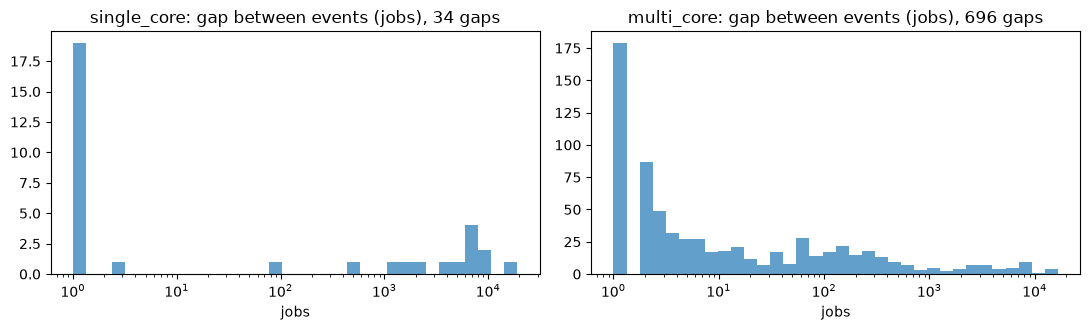

In [16]:
rows, G = [], {s: [] for s in SCENARIOS}
for r in RUNS:
    g = np.diff(EV[r])
    G[r[0]].append(g)
    rows.append(dict(run=label(r), events=len(EV[r]), mean_gap=g.mean() if len(g) else np.nan, median_gap=np.median(g) if len(g) else np.nan,
                     share_gap_below_50=(g <= 50).mean() if len(g) else np.nan, ks_exp_p=kstest(g / g.mean(), expon.cdf).pvalue if len(g) > 10 else np.nan))
display(pd.DataFrame(rows).set_index("run").round(3))
fig, ax = plt.subplots(1, len(SCENARIOS), figsize=(11, 3.4))
for a, s in zip(ax, SCENARIOS):
    g = np.concatenate(G[s]); bins = np.logspace(0, np.log10(g.max()), 35)
    a.hist(g, bins=bins, alpha=.7); a.set_xscale("log"); a.set_title(f"{s}: gap between events (jobs), {len(g)} gaps"); a.set_xlabel("jobs")
plt.tight_layout(); plt.show()

### 3.3 Are the events the same in the two instances? (multi-core)
Jobs with the same `job_id` run in the same period on the two cores. `both` = jobs that are events in both instances; `expected` = what independent instances would give (events₀ × events₁ / jobs). Many more than expected means the events come from the platform (the VM), not from the task.

In [17]:
rows = []
for c in CONDITIONS:
    a, b = frames[("multi_core", c, "instance0")], frames[("multi_core", c, "instance1")]
    m = a.merge(b, on="job_id", suffixes=("0", "1"))
    ea = m.cpu_ns0 / 1e6 > EVENT_FACTOR * np.median(X[("multi_core", c, "instance0")])
    eb = m.cpu_ns1 / 1e6 > EVENT_FACTOR * np.median(X[("multi_core", c, "instance1")])
    rows.append(dict(condition=c, events0=int(ea.sum()), events1=int(eb.sum()), both=int((ea & eb).sum()), expected=ea.sum() * eb.sum() / len(m)))
display(pd.DataFrame(rows).set_index("condition").round(3))

,events0,events1,both,expected
condition,,,,
baseline1,9,9,9,0.002
cache,12,11,11,0.003
memory,372,269,123,2.003
baseline2,4,18,2,0.001


### 3.4 Is it the content or the platform?
`frame_idx` is `job_id` modulo the 3269 pictures: the pictures are cycled, and the same job of two runs processes the same picture. If the content drove C, the C of the same job would be correlated between two runs (baseline1 against baseline2). A correlation near 0 means the variation is not a property of the picture. The correlation is shown for all jobs and for the 1 % largest jobs of baseline1.

In [18]:
rows = []
for s in SCENARIOS:
    for i in SCENARIOS[s]:
        a, b = frames[(s, "baseline1", i)], frames[(s, "baseline2", i)]
        m = a.merge(b, on="job_id", suffixes=("1", "2"))
        top = m.cpu_ns1 >= m.cpu_ns1.quantile(.99)
        rows.append(dict(scenario=s, instance=i, jobs=len(m), corr_all=np.corrcoef(m.cpu_ns1, m.cpu_ns2)[0, 1],
                         corr_log_all=np.corrcoef(np.log(m.cpu_ns1), np.log(m.cpu_ns2))[0, 1],
                         top1pct_of_run1_also_top1pct_in_run2=float((m.cpu_ns2[top] >= m.cpu_ns2.quantile(.99)).mean())))
display(pd.DataFrame(rows).set_index(["scenario", "instance"]).round(3))

jobs  corr_all  corr_log_all  top1pct_of_run1_also_top1pct_in_run2
scenario    instance                                                                      
single_core instance0  50000    -0.355        -0.364                                 0.008
multi_core  instance0  50000     0.054         0.054                                 0.008
            instance1  50000     0.072         0.072                                 0.014

### 3.5 What if the events are taken out of the block maxima?
GEV fitted only to the jobs that are not events (the event jobs are removed from the series before the block maxima are taken), against the full series. The events remain part of what the task experiences, so this is **not** a budget; it checks whether the rest of the series is a well-behaved GEV input, which would confirm that the mixture is what breaks the fit.

In [19]:
rows = []
for r in RUNS:
    x = X[r]; med = np.median(x); xb = x[x <= EVENT_FACTOR * med]
    th = extremal_index(xb); adm = [b for b in BLOCK_GRID if b >= MIN_B and len(xb) // b >= MIN_BLOCKS]
    v = [gev_bound(xb, b, th=th)[0] for b in adm]
    rows.append(dict(run=label(r), removed=len(x) - len(xb), p_full=gof_p(block_maxima(x, BLOCK_CHOSEN)), p_without_events=gof_p(block_maxima(xb, BLOCK_CHOSEN)),
                     xi_full=gev_bound(x, BLOCK_CHOSEN)[1], xi_without=gev_bound(xb, BLOCK_CHOSEN, th=th)[1],
                     spread_without=max(v) / min(v), bound_full=gev_bound(x, BLOCK_CHOSEN)[0], bound_without=gev_bound(xb, BLOCK_CHOSEN, th=th)[0],
                     emp_full=np.quantile(x, 1 - P_GEV)))
nev = pd.DataFrame(rows).set_index("run")
display(nev.round(3))

,removed,p_full,p_without_events,xi_full,xi_without,spread_without,bound_full,bound_without,emp_full
run,,,,,,,,,
singl/baseline1/0,5,0.010,0.010,0.344,-0.012,1.003,50.957,50.721,51.087
singl/cache/0,14,0.010,0.020,0.310,-0.214,1.004,54.921,53.959,54.655
singl/memory/0,9,0.010,0.386,0.296,-0.239,1.003,54.221,53.780,54.236
singl/baseline2/0,10,0.010,0.129,0.190,-0.192,1.002,50.909,50.583,50.784
multi/baseline1/0,9,0.505,0.168,0.476,0.203,1.004,51.701,51.357,51.866
multi/baseline1/1,9,0.020,0.792,0.416,0.146,1.003,51.708,51.395,51.530
multi/cache/0,12,0.010,0.168,0.490,0.012,1.001,42.992,42.342,42.442
multi/cache/1,11,0.198,0.733,0.462,0.056,1.002,54.944,54.201,54.592
multi/memory/0,372,0.010,0.010,0.599,-1.302,1.008,60.081,57.893,60.060


## 4. Summary per run
One row per run: the verdict of the stability criteria (1.6), the fit diagnostic, and the evidence for each assumption.
- **dependence:** autocorrelation at lag 100.
- **stationarity:** `level_range_sigma` of 2.1 (about 0.2 for an iid series).
- **one regime:** `gap` of 3.1 (ratio of the maxima of event blocks to bulk blocks; 1 = one regime).
- **Poisson events:** dispersion of 3.1.

In [20]:
summ = verdict[["emp", "spread", "halves", "vs_emp", "stable", f"p b={BLOCK_CHOSEN}", "estimator"]].join(
    stat[["acf100", "level_range_sigma"]]).join(reg[["per_100k", "gap", "bimodality", "dispersion"]])
display(summ.round(3))

,emp,spread,halves,vs_emp,stable,p b=500,estimator,acf100,level_range_sigma,per_100k,gap,bimodality,dispersion
run,,,,,,,,,,,,,
singl/baseline1/0,51.087,1.010,1.011,-0.003,True,0.010,GEV bound,0.666,2.532,10.000,1.460,0.900,2.150
singl/cache/0,54.655,1.008,1.026,0.005,True,0.010,GEV bound,0.573,3.517,28.001,1.450,0.877,3.716
singl/memory/0,54.236,1.011,1.006,-0.000,True,0.010,GEV bound,0.604,2.695,18.000,1.394,0.872,3.354
singl/baseline2/0,50.784,1.007,1.013,0.002,True,0.010,GEV bound,0.663,2.929,20.000,1.197,0.837,5.100
multi/baseline1/0,51.866,1.009,1.040,-0.003,True,0.505,GEV bound,0.705,2.083,18.000,1.201,0.784,1.354
multi/baseline1/1,51.530,1.008,1.012,0.003,True,0.020,GEV bound,0.707,1.993,18.000,1.188,0.814,1.354
multi/cache/0,42.442,1.003,1.018,0.013,True,0.010,GEV bound,0.384,2.391,24.000,1.212,0.830,1.713
multi/cache/1,54.592,1.006,1.021,0.006,True,0.198,GEV bound,0.375,2.305,22.000,1.198,0.826,1.799
multi/memory/0,60.060,1.020,1.138,0.000,False,0.010,empirical (bootstrap) bound,0.868,6.625,744.476,1.121,0.584,34.665


## 5. Conclusions (workload2, 12 runs of 50k jobs, period 100 ms)

**Settings for `analysis_workload2.ipynb`:** `BLOCK = 500` (100 blocks), `L_BOOT = 500`, `RUNS_R = 50` (sections 1.1, 1.5).
- The GEV bound at `P_GEV` is stable in **10 of 12 runs** (spread over b = 500–1000 at most 1.1 %, halves at most 4 %, within 2 % of the empirical quantile). The two that fail are the multi-core runs under the memory enemy (halves 1.14 and 1.17; the bound falls from 85 to 58 ms for instance 0 as b goes from 100 to 1000).
- The bootstrap bound is flat in `L` from 100 to 5000 (changes below 1 %); `L_BOOT = 500` equals the block.
- `θ` has no plateau (0.7 → 0.3 as the gap grows from 10 to 500 jobs, in every single-core run), so `RUNS_R = 50` is again a choice on the conservative side (the bound grows 1–2 % from r = 50 to 200, 4.5 % for multi-core memory instance 1).
- The bootstrap goodness of fit rejects (p < 0.05) in **10 of 12 runs** at b = 500, although their bounds are stable: here the diagnostic and the bound disagree, and the bound is what the budgets use.

**What breaks the block-maxima GEV in this workload** (sections 2 and 3):
1. **Stationarity: broken, and it is the main cause.** The level of C moves in plateaus with steps: autocorrelation 0.55–0.74 at lag 1 and 0.38–0.71 at lag 100 (0.87–0.88 for multi-core memory), still 0.19–0.45 at lag 3269 (one pass over the pictures) in 8 of 12 runs; the block medians span 2–3.5 σ (6–6.6 σ for multi-core memory) and a trend is significant in 8 runs. In multi-core memory the level steps up by about 9 % late in the run in both instances, which is what makes its bound depend on the half of the run used.
2. **The steps are common to both instances** (correlation of the steps 0.98–0.997): the modulation comes from the platform (frequency, neighbours), not from the task. A block maximum is then mostly the level of its plateau plus noise, so the maxima follow the distribution of the few plateaus visited during one run, not an extreme-value law. Removing the level (2.5) changes the bound by 0.5–2.5 %, and by 6 % for multi-core memory instance 0 (60.1 → 56.4 ms).
3. **Rare events exist but are a minor part:** 4–18 jobs per run above 1.15 × the median (apart from multi-core memory, where the threshold lies inside the high plateau); the maxima of event blocks are only 1.1–1.5 times those of the others (against 1.4–1.9 in workload3). In multi-core baseline1 and cache every event is an event in both instances at once (9 of 9 and 11 of 12; fewer than 0.003 expected), and 123 of 269 under the memory enemy: platform events.
4. **The picture does not drive C** (3.4): the same job in two runs is not positively correlated (the negative values come from opposite drifts in the two runs).
5. **Something is wrong with multi-core baseline2.** The two instances differ persistently: the ratio of their medians is 1.27 in baseline2 and 1.28 under the memory enemy, 0.78 under the cache enemy and 1.00 in baseline1 (2.6). A baseline without any enemy should look like baseline1. Check the profiling log for the enemy during that run (its start is 17:29 UTC, one minute after the memory run ended); if the interference is confirmed, baseline2 of multi-core should be rerun before its numbers are used (they enter the baseline envelope and α_drift).

**Consequence for the budgets.** At `P_GEV = 1e-3` the bound is an interpolation in the data, so it is stable and close to the empirical quantile although the model assumption is violated. The bound describes the regimes that occurred in that run, which is the job of α_drift and not of a better tail fit. For multi-core memory the empirical bootstrap bound should be used.